# MECH0074 Part B · Stage 1 — LNG water hammer
Open this notebook in VS Code, select a Python kernel with NumPy and Matplotlib, then choose **Run All**. If needed, install them into the selected environment with `python -m pip install numpy matplotlib ipykernel`.

**Provenance.** The MOC solver below is carried over from the supplied teaching notebook `water_hammer_valve_closure_and_bend_forces2-2.ipynb`. This adaptation adds the LNG inputs from `MECH0074_CW1_2026_27_v6.pdf`, the four pressure traces, timing and pressure checks, a frequency estimate, and a resolution comparison.

**Benchmark.** A horizontal, constant-area 100 m pipe runs from a constant-pressure reservoir (`x = 0`) to a valve (`x = 100 m`). The valve velocity decreases linearly to zero. This verification case assumes single-phase flow, zero friction and a constant wave speed of 1100 m/s (the supplied LNG bulk sound speed, used here as the benchmark wave speed without a pipe-wall compliance correction).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

g = 9.81
p_atm = 101_325.0       # external absolute pressure, Pa
p_initial = 700_000.0   # initial absolute pressure, Pa
L, D, a = 100.0, 0.79394, 1100.0
rho, u0, tc = 455.0, 1.5, 0.02
stations = (10.0, 25.0, 50.0, 100.0)

# The supplied solver expects gauge pressure head (m of the model liquid).
case = dict(length=L, diameter=D, wave_speed=a, density=rho,
            initial_velocity=u0, closure_time=tc, friction_factor=0.0,
            reservoir_head=(p_initial - p_atm) / (rho * g))

## Supplied solver
The method of characteristics propagates information one grid interval per time step, so Δt = Δx/a. The fixed reservoir head and prescribed valve flow are applied at opposite ends.

In [2]:
def simulate_water_hammer(
    length=600.0,
    diameter=0.30,
    wave_speed=1000.0,
    friction_factor=0.020,
    initial_velocity=1.0,
    reservoir_head=120.0,
    closure_time=0.01,
    density=998.0,
    n_reaches=80,
    n_round_trips=4.0,
    simulation_time=None,
):
    """MOC solution for a reservoir-pipe-valve system.

    Head is gauge piezometric head relative to the pipe elevation. The valve
    boundary has a prescribed linear reduction of volume flow to zero.
    """
    values = [length, diameter, wave_speed, initial_velocity, density, n_reaches]
    if min(values) <= 0 or closure_time <= 0 or friction_factor < 0:
        raise ValueError("Physical dimensions, speed, density and closure time must be positive.")

    n_reaches = int(n_reaches)
    area = np.pi * diameter**2 / 4
    dx = length / n_reaches
    dt = dx / wave_speed                      # exact rectangular characteristic grid
    round_trip = 2 * length / wave_speed
    end_time = (closure_time + n_round_trips * round_trip
                if simulation_time is None else float(simulation_time))
    if end_time <= 0:
        raise ValueError("Simulation time must be positive.")
    n_steps = int(np.ceil(end_time / dt))

    x = np.linspace(0.0, length, n_reaches + 1)
    time = np.arange(n_steps + 1) * dt
    H = np.empty((n_steps + 1, n_reaches + 1), dtype=float)
    Q = np.empty_like(H)

    Q_initial = area * initial_velocity
    # Horizontal steady-state head profile with Darcy-Weisbach loss.
    H_initial = reservoir_head - friction_factor * x * initial_velocity**2 / (2 * g * diameter)
    H[0] = H_initial
    Q[0] = Q_initial

    B = wave_speed / (g * area)
    R = friction_factor * dx / (2 * g * diameter * area**2)

    for n in range(n_steps):
        h_old, q_old = H[n], Q[n]

        # Interior nodes: one compatibility relation arrives from each side.
        c_plus = h_old[:-2] + B*q_old[:-2] - R*q_old[:-2]*np.abs(q_old[:-2])
        c_minus = h_old[2:] - B*q_old[2:] + R*q_old[2:]*np.abs(q_old[2:])
        H[n+1, 1:-1] = 0.5 * (c_plus + c_minus)
        Q[n+1, 1:-1] = (c_plus - c_minus) / (2 * B)

        # Upstream reservoir: fixed head; incoming C- comes from node 1.
        c_minus_res = h_old[1] - B*q_old[1] + R*q_old[1]*abs(q_old[1])
        H[n+1, 0] = reservoir_head
        Q[n+1, 0] = (H[n+1, 0] - c_minus_res) / B

        # Downstream valve: prescribed linear flow closure.
        c_plus_valve = h_old[-2] + B*q_old[-2] - R*q_old[-2]*abs(q_old[-2])
        opening = max(1.0 - time[n+1] / closure_time, 0.0)
        Q[n+1, -1] = Q_initial * opening
        H[n+1, -1] = c_plus_valve - B * Q[n+1, -1]

    return {
        "x": x,
        "time": time,
        "H": H,
        "Q": Q,
        "H_initial": H_initial,
        "area": area,
        "dx": dx,
        "dt": dt,
        "B": B,
        "R": R,
        "round_trip": round_trip,
        "density": density,
        "diameter": diameter,
        "wave_speed": wave_speed,
        "initial_velocity": initial_velocity,
        "closure_time": closure_time,
        "reservoir_head": reservoir_head,
        "friction_factor": friction_factor,
        "Q_initial": Q_initial,
    }

## First second: pressure rise and wave arrival
Plot absolute pressure. The dashed lines indicate theoretical arrival at each upstream station. For a linear closure, the first sample with a measurable increase is expected one step after the wavefront on this grid.

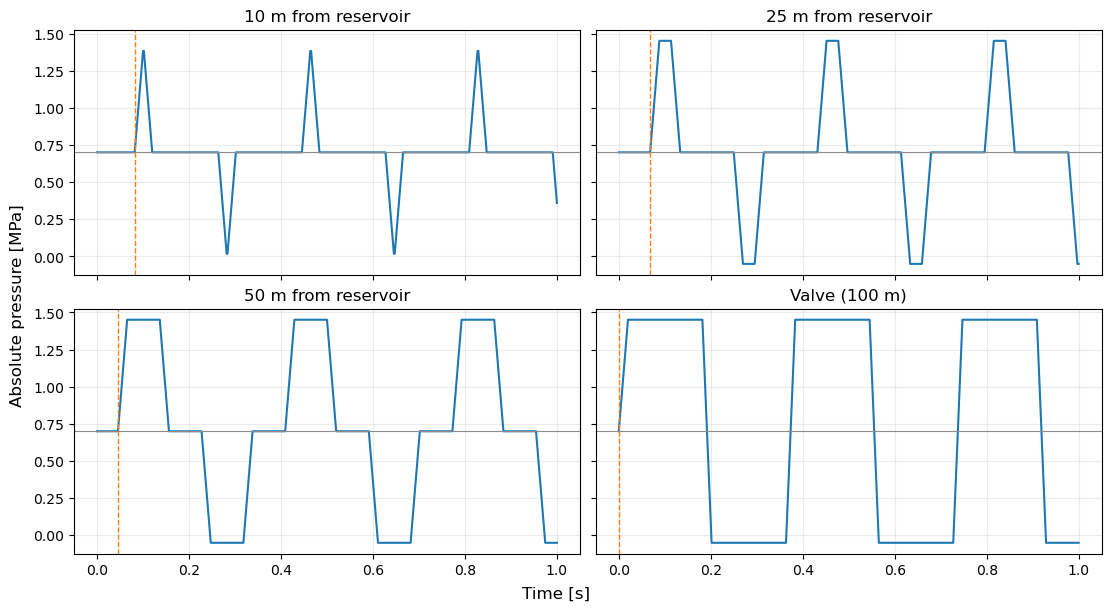

Closure: 0.020 s; wave round trip 2L/a: 0.181818 s
One-way travel L/a: 0.090909 s
First valve rise: MOC 0.750750 MPa; Joukowsky 0.750750 MPa
Station [m]   Theory front [s]   First rise sample [s]   Delay [ms]
         10           0.081818                0.082273        0.455
         25           0.068182                0.068636        0.455
         50           0.045455                0.045909        0.455
        100           0.000000                0.000455        0.455


In [3]:
def station_index(result, station):
    i = int(np.argmin(np.abs(result["x"] - station)))
    if not np.isclose(result["x"][i], station, rtol=0, atol=1e-9):
        raise ValueError(f"Station {station:g} m is off-grid; adjust n_reaches.")
    return i

def pressure_at(result, station):
    return p_atm + rho * g * result["H"][:, station_index(result, station)]

baseline = simulate_water_hammer(**case, n_reaches=200, simulation_time=1.0)
t = baseline["time"]
keep = t <= 1.0 + 1e-12
fig, axes = plt.subplots(2, 2, figsize=(11, 6), sharex=True, sharey=True,
                         layout="constrained")
for x, ax in zip(stations, axes.flat):
    ax.plot(t[keep], pressure_at(baseline, x)[keep] / 1e6)
    ax.axhline(p_initial / 1e6, color="0.55", lw=0.8)
    ax.axvline((L-x)/a, ls="--", color="tab:orange", lw=1)
    ax.set_title("Valve (100 m)" if x == L else f"{x:g} m from reservoir")
    ax.grid(alpha=0.25)
fig.supxlabel("Time [s]")
fig.supylabel("Absolute pressure [MPa]")
plt.show()

def first_positive_sample(result, x):
    p = pressure_at(result, x)
    i = np.flatnonzero(p - p[0] > 1.0)[0]  # 1 Pa detection threshold
    return result["time"][i]

def first_valve_rise(result):
    p = pressure_at(result, L)
    before_return = result["time"] < 2 * L / a
    return np.max(p[before_return]) - p[0]

dp_theory = rho * a * u0
print(f"Closure: {tc:.3f} s; wave round trip 2L/a: {2*L/a:.6f} s")
print(f"One-way travel L/a: {L/a:.6f} s")
print(f"First valve rise: MOC {first_valve_rise(baseline)/1e6:.6f} MPa; "
      f"Joukowsky {dp_theory/1e6:.6f} MPa")
print("Station [m]   Theory front [s]   First rise sample [s]   Delay [ms]")
for x in stations:
    expected = (L-x)/a
    observed = first_positive_sample(baseline, x)
    print(f"{x:11.0f}   {expected:16.6f}   {observed:21.6f}   "
          f"{1000*(observed-expected):10.3f}")

## Longer run: period and dominant frequency
Use a 10 s valve record. Estimate the period from successive upward crossings of the initial pressure, with linear interpolation between samples. Separately estimate the dominant frequency from the largest nonzero FFT bin. The FFT bin spacing is approximately 0.1 Hz, so the FFT estimate is coarser than the crossing estimate.

Period from crossings: 0.363636 s; theory 4L/a: 0.363636 s
Frequency from crossings: 2.7500 Hz; theory: 2.7500 Hz
Dominant FFT bin: 2.6999 Hz; bin spacing: 0.1000 Hz
Minimum predicted absolute pressure: -0.050750 MPa at valve


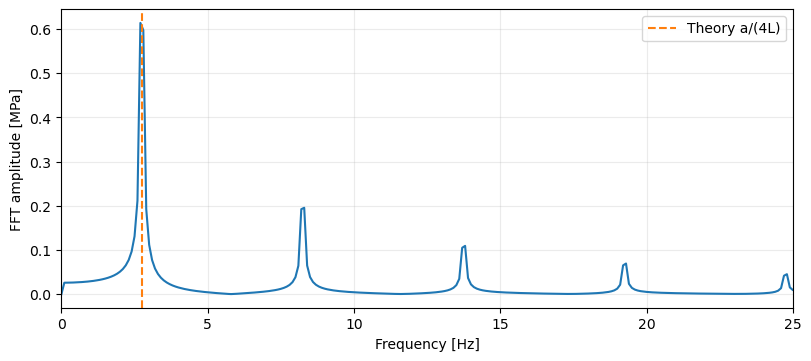

In [4]:
def measured_period(result):
    t = result["time"]
    y = pressure_at(result, L) - p_initial
    hits = np.flatnonzero((t[:-1] > tc) & (y[:-1] <= 0) & (y[1:] > 0))
    crossings = t[hits] - y[hits] * (t[hits+1] - t[hits]) / (y[hits+1] - y[hits])
    return np.mean(np.diff(crossings))

long_run = simulate_water_hammer(**case, n_reaches=200, simulation_time=10.0)
p_valve = pressure_at(long_run, L)
freq = np.fft.rfftfreq(p_valve.size, d=long_run["dt"])
amplitude = 2 * np.abs(np.fft.rfft(p_valve - p_valve.mean())) / p_valve.size
peak_bin = 1 + np.argmax(amplitude[1:])
period = measured_period(long_run)
print(f"Period from crossings: {period:.6f} s; theory 4L/a: {4*L/a:.6f} s")
print(f"Frequency from crossings: {1/period:.4f} Hz; theory: {a/(4*L):.4f} Hz")
print(f"Dominant FFT bin: {freq[peak_bin]:.4f} Hz; bin spacing: {freq[1]:.4f} Hz")
print(f"Minimum predicted absolute pressure: {p_valve.min()/1e6:.6f} MPa at valve")

fig, ax = plt.subplots(figsize=(8, 3.5), layout="constrained")
ax.plot(freq, amplitude / 1e6)
ax.axvline(a/(4*L), ls="--", color="tab:orange", label="Theory a/(4L)")
ax.set(xlim=(0, 25), xlabel="Frequency [Hz]", ylabel="FFT amplitude [MPa]")
ax.grid(alpha=0.25)
ax.legend()
plt.show()

## Resolution check
All four stations lie on each grid. Compare the first valve pressure rise, the first detectable rise at 50 m, and the valve period. A flat result for pressure rise and period is expected for this ideal characteristic-grid case; the first detectable arrival should move toward the theoretical wavefront as Δt decreases.

In [ ]:
print("Cells   dx [m]   dt [ms]   Valve rise [MPa]   50 m first rise [s]   Period [s]")
for n in (100, 200, 400):
    result = simulate_water_hammer(**case, n_reaches=n, simulation_time=2.0)
    print(f"{n:5d}   {result['dx']:6.3f}   {1e3*result['dt']:7.4f}   "
          f"{first_valve_rise(result)/1e6:16.6f}   "
          f"{first_positive_sample(result, 50.0):19.6f}   "
          f"{measured_period(result):10.6f}")

## Interpretation and limits
The first pressure rise is the compression wave generated at the valve. The reservoir holds its pressure constant, so it reflects the compression as a pressure-relief wave. The complete cycle is 4L/a; 2L/a is only the round trip.

The ideal calculation can predict negative absolute pressure after reflection. This is outside the physical validity of the single-phase LNG model. The plotted continuation and its frequency describe the **ideal benchmark**, not the pressure history of a real line experiencing vapor formation or column separation. The model does not impose a pressure floor or use the original notebook's water vapor-pressure threshold.